# Exploring the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/RRCA_baseflow.csv')

# Date is a matlab day number
df['DateTime'] = pd.to_datetime(df['Date'] - 719529, unit='D')
df['DateTime'].head(10)

0   1945-12-01
1   1946-01-01
2   1946-01-29
3   1946-03-01
4   1946-03-31
5   1946-05-01
6   1946-05-31
7   1946-07-01
8   1946-08-01
9   1946-08-31
Name: DateTime, dtype: datetime64[us]

Jan 29 shows up right after Jan 1 so some of these are actually the next month. Rounding to the nearest month fixes it.

In [2]:
df['DateTime'] = (df['DateTime'] + pd.Timedelta(days=15)).dt.to_period('M').dt.to_timestamp()
df['Year'] = df['DateTime'].dt.year
df['Month'] = df['DateTime'].dt.month

# pumping is stored as negative numbers
df['Pumping'] = df['Irrigation_pumping'] * -1

display(df.head(5))
df.describe()

,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,DateTime,Year,Month,Pumping
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-12-01,1945,12,-0.0
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,1946-01-01,1946,1,-0.0
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-02-01,1946,2,-0.0
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-03-01,1946,3,-0.0
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-04-01,1946,4,-0.0


,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,DateTime,Year,Month,Pumping
count,15591.000000,15591.000000,1.559100e+04,1.559100e+04,15591.000000,15591.000000,15591.000000,15591.000000,15591,15591.000000,15591.000000,15591.000000
mean,719206.175358,126.589892,1.169435e+06,1.457066e+07,2.687491,14.915469,-0.090713,23.986754,1969-02-12 17:42:20.157784,1968.662882,6.484895,0.090713
min,708479.000000,40.000000,7.218700e+05,1.438704e+07,0.000000,0.000000,-3.164700,-22.000000,1939-10-01 00:00:00,1939.000000,1.000000,-0.000000
25%,713623.000000,64.000000,9.066700e+05,1.454544e+07,0.000000,0.000000,-0.012000,1.985455,1953-11-01 00:00:00,1953.000000,4.000000,-0.000000
50%,718858.000000,145.000000,1.170670e+06,1.456128e+07,1.040000,17.490000,0.000000,7.703934,1968-03-01 00:00:00,1968.000000,6.000000,0.000000
75%,724642.000000,171.000000,1.392430e+06,1.461936e+07,5.340000,22.370000,0.000000,22.804139,1984-01-01 00:00:00,1984.000000,9.000000,0.012000
max,730729.000000,256.000000,1.941550e+06,1.476720e+07,12.100000,40.380000,0.000000,747.803280,2000-09-01 00:00:00,2000.000000,12.000000,3.164700
std,6287.339388,52.789605,2.924991e+05,8.331048e+04,3.167235,10.512909,0.273726,56.275292,NaN,17.216659,3.444271,0.273726


## Segments

There are duplicate segment/date rows, checking why

In [3]:
df.groupby('Segment_id')[['x', 'y']].nunique().sort_values('x', ascending=False).head()

,x,y
Segment_id,,
53,2,2
159,2,2
171,2,2
152,2,2
51,1,1


In [4]:
df[df['Segment_id'] == 53].groupby(['x', 'y'])['Observed'].agg(['count', 'mean'])

,,count,mean
x,y,,
991150,14714400,120,19.227989
1049230,14666880,120,104.405916


Some segments have 2 gauges at different spots with really different flows, so I'm making a station id from x/y instead of using Segment_id.

In [5]:
df['Station'] = df.groupby(['x', 'y']).ngroup()
df['Station'].nunique()

46

In [6]:
df.groupby('Station').agg({'Segment_id': 'first', 'Year': ['min', 'max'], 'Observed': 'count'})

Segment_id  Year       Observed
             first   min   max    count
Station                                
0               98  1950  1976      315
1               97  1950  1971      257
2              130  1939  2000      732
3              176  1945  1956      123
4               96  1939  2000      732
5               65  1940  2000      708
6              123  1939  1940        8
7               59  1940  2000      720
8              147  1941  1994      645
9              178  1939  2000      706
10             188  1946  1994      576
11             194  1939  1945       72
12              53  1940  1950      120
13             157  1939  1950      133
14              53  1939  1949      120
15             144  1945  2000      118
16             205  1939  1949      116
17              55  1946  1986      482
18             154  1962  1969       56
19              60  1960  2000      480
20              51  1959  2000      495
21              56  1946  2000      653
22             159  1940  1948       90
23             118  1951  1958       85
24             136  1951  1958       89
25             145  1944  2000      399
26             159  1939  1960      252
27             135  1951  1994      285
28             170  1950  1999      596
29             186  1939  1948      108
30             146  1962  2000      459
31             152  1995  2000       60
32             171  1944  1964      246
33             149  1951  1999      489
34             152  1939  1972      396
35             189  1939  1999      718
36             138  1977  2000      276
37             196  1946  2000      656
38             171  1945  2000      447
39              62  1948  1953       66
40              63  1948  1956      102
41             239  1939  1949      119
42              64  1948  1994      393
43             148  1948  1999      450
44              40  1948  1999      324
45             256  1939  1949      119

## Zeros

In [7]:
(df['Precipitation'] == 0).mean()

np.float64(0.2832403309601693)

In [8]:
df.groupby('Station')['Precipitation'].apply(lambda x: (x == 0).mean()).sort_values(ascending=False).head(12)

Station
0     1.000000
34    1.000000
37    1.000000
25    1.000000
21    1.000000
20    1.000000
30    1.000000
32    1.000000
35    1.000000
38    0.176734
2     0.000000
3     0.000000
Name: Precipitation, dtype: float64

In [9]:
df[df['Station'] == 0][['Precipitation', 'Evapotranspiration', 'Pumping']].describe()

,Precipitation,Evapotranspiration,Pumping
count,315.0,315.0,315.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,-0.0
25%,0.0,0.0,-0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,-0.0
max,0.0,0.0,-0.0


In [10]:
df[(df['Station'] == 38) & (df['Precipitation'] == 0)]['Year'].unique()

array([1994, 1995, 1996, 1997, 1998, 1999, 2000], dtype=int32)

9 stations have 0 for precipitation, ET, and pumping the entire time so that's missing data not real zeros. Station 38 loses its precipitation after 1994.

Also precipitation looks like the same number every month of a year:

In [11]:
df[df['Station'] == 15][['DateTime', 'Precipitation', 'Evapotranspiration']].head(15)

,DateTime,Precipitation,Evapotranspiration
0,1945-12-01,18.99,0.59
1,1946-01-01,29.63,0.97
2,1946-02-01,29.63,1.34
3,1946-03-01,29.63,1.79
4,1946-04-01,29.63,8.23
5,1946-05-01,29.63,5.12
6,1946-06-01,29.63,8.41
7,1946-07-01,29.63,7.94
8,1946-08-01,29.63,7.79
9,1946-09-01,29.63,4.24


So precipitation is yearly. A whole year with 0 rain isn't realistic so I'm dropping rows where precipitation is 0.

In [12]:
df = df[df['Precipitation'] > 0]
print(len(df), df['Station'].nunique())

11175 37


## Baseflow

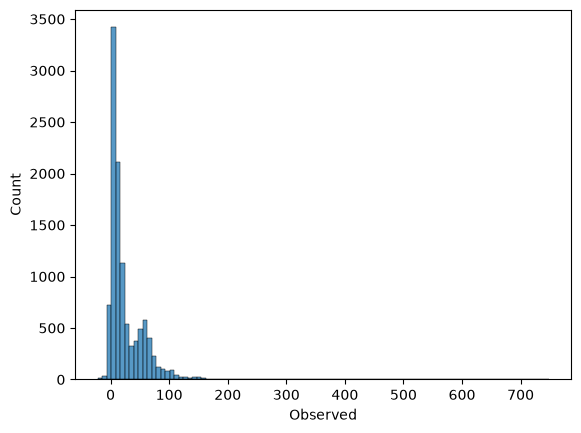

In [13]:
sns.histplot(df['Observed'], bins=100)
plt.show()

In [14]:
df[df['Observed'] < 0]['Station'].value_counts()

Station
9    222
3     10
Name: count, dtype: int64

Super skewed, most is under 25 but a few go over 700. Negatives are almost all station 9, which is probably a losing stream (river leaking into the ground). Keeping them since they're real.

## Map

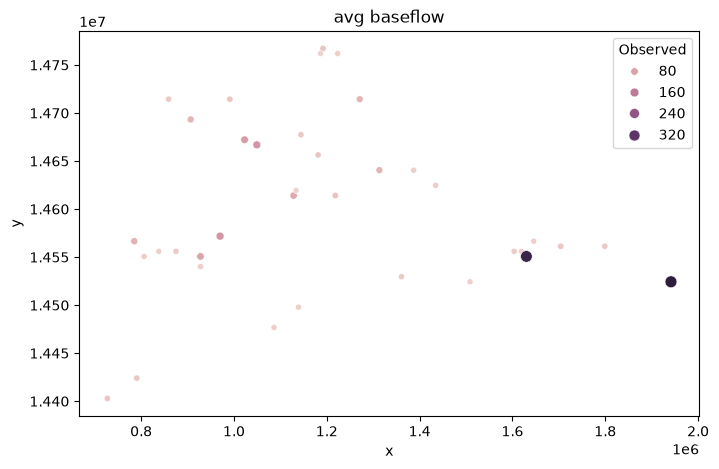

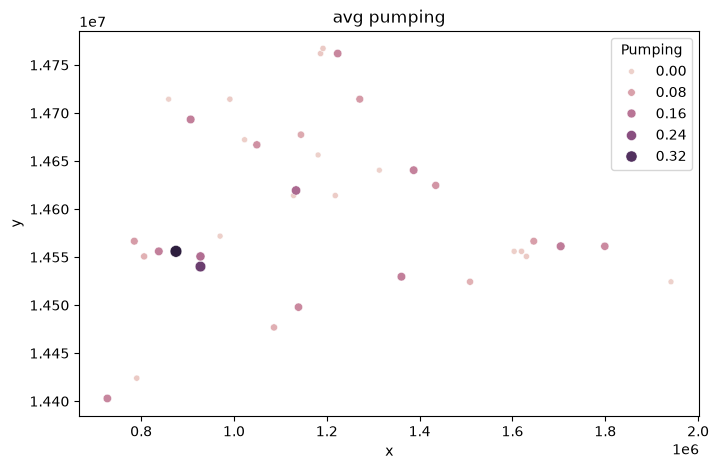

In [15]:
station_means = df.groupby('Station')[['x', 'y', 'Observed', 'Pumping']].mean()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=station_means, x='x', y='y', hue='Observed', size='Observed')
plt.title('avg baseflow')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=station_means, x='x', y='y', hue='Pumping', size='Pumping')
plt.title('avg pumping')
plt.show()

The two biggest baseflow stations are on the east end (downstream, river flows into Kansas). Most pumping is on the west side.

## Over time

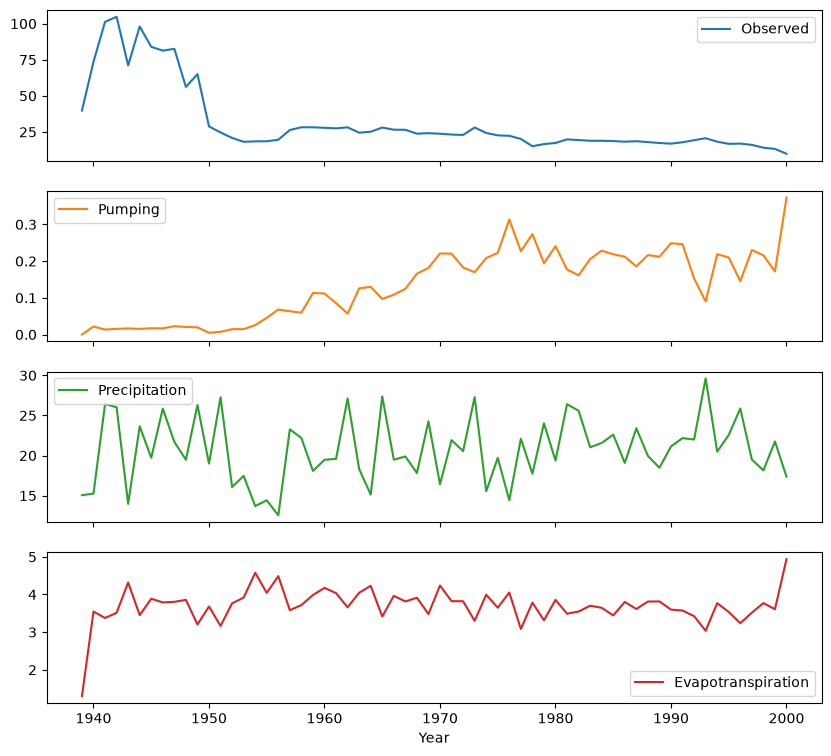

In [16]:
yearly = df.groupby('Year')[['Observed', 'Pumping', 'Precipitation', 'Evapotranspiration']].mean()
yearly.plot(subplots=True, figsize=(10, 9))
plt.show()

Baseflow drops a ton around 1950 but I think that's just some big stations stop getting recorded then. Pumping starts in the mid 50s and goes up until about 1980. Rain and ET don't really trend.

## Looking at single stations

In [17]:
station_means.sort_values('Pumping', ascending=False).head()

,x,y,Observed,Pumping
Station,,,,
7,874990.0,14556000.0,11.917548,0.374238
9,927790.0,14540160.0,7.657653,0.282741
17,1133710.0,14619360.0,1.449889,0.182822
10,927790.0,14550720.0,77.848250,0.172917
43,1703950.0,14561280.0,19.619108,0.147615


Picking station 7 (lots of pumping and a long record), station 4 (not much pumping), and station 9 (the losing stream).

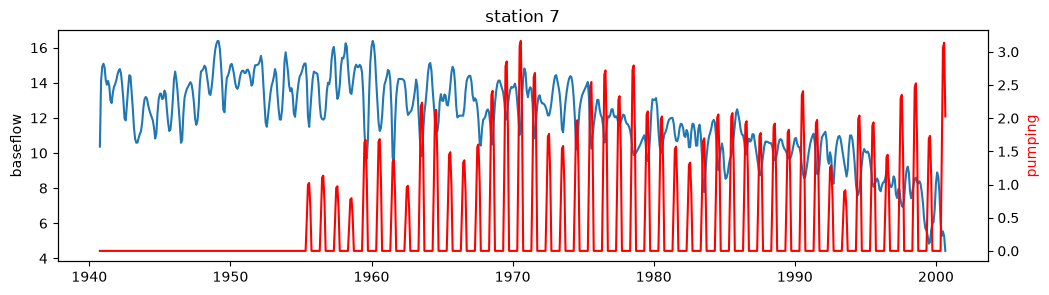

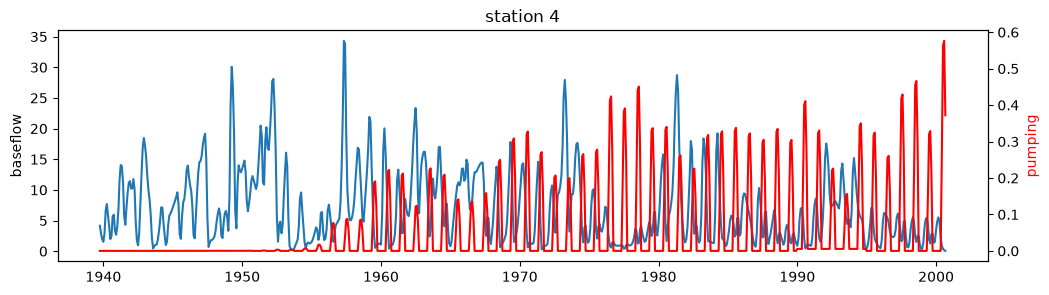

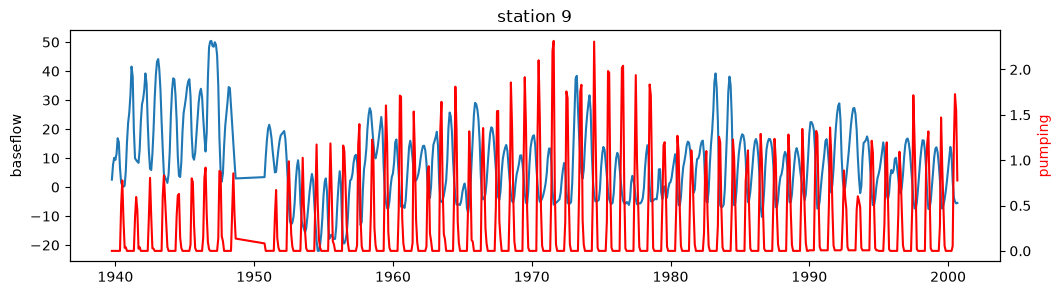

In [18]:
for s in [7, 4, 9]:
    d = df[df['Station'] == s]
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(d['DateTime'], d['Observed'])
    ax.set_ylabel('baseflow')
    ax2 = ax.twinx()
    ax2.plot(d['DateTime'], d['Pumping'], color='red')
    ax2.set_ylabel('pumping', color='red')
    plt.title('station ' + str(s))
    plt.show()

Pumping only happens in summer, so it's gonna be tied up with month. Station 7 slowly drops after pumping starts in the 50s. Station 9 starts going negative in the summers once pumping picks up.

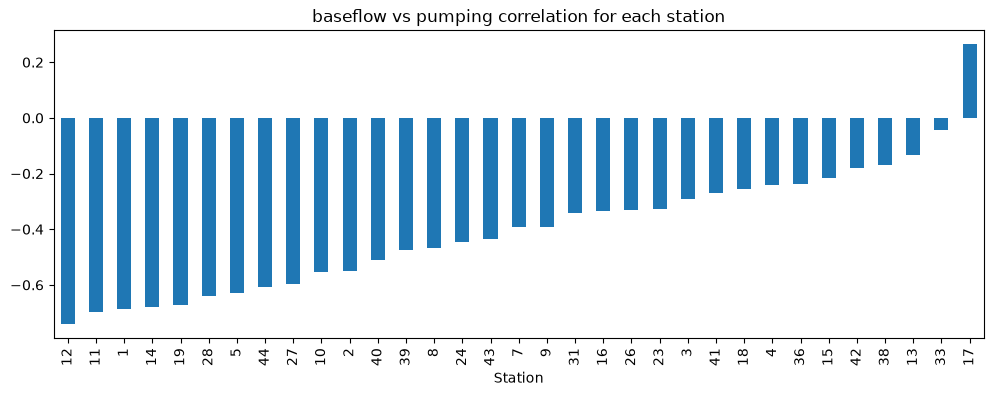

In [19]:
corrs = []
for s in df['Station'].unique():
    d = df[df['Station'] == s]
    if d['Pumping'].max() > 0:
        corrs.append([s, d['Observed'].corr(d['Pumping'])])

corrs = pd.DataFrame(corrs, columns=['Station', 'corr']).sort_values('corr')
corrs.plot(x='Station', y='corr', kind='bar', figsize=(12, 4), legend=False)
plt.title('baseflow vs pumping correlation for each station')
plt.show()

Inside basically every station more pumping = less baseflow. Only station 17 goes the other way.

## Baseflow vs everything

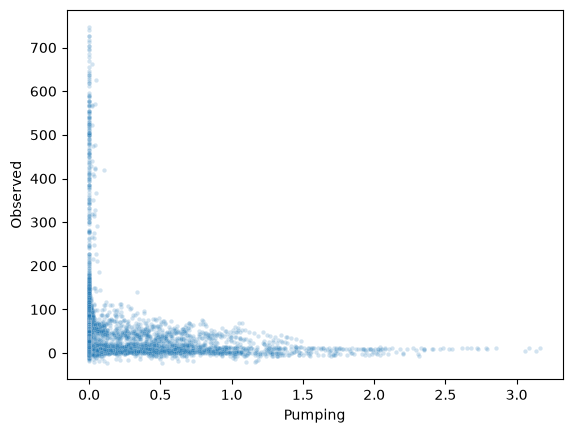

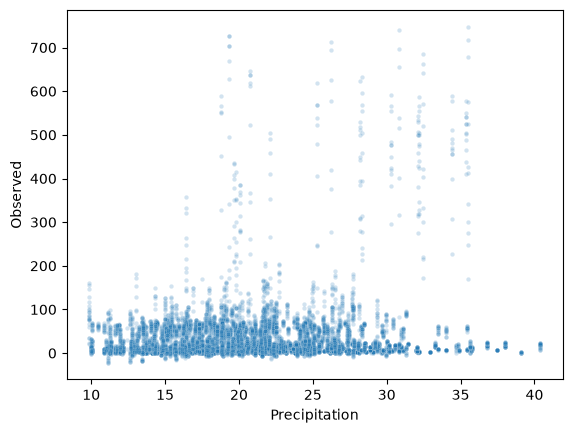

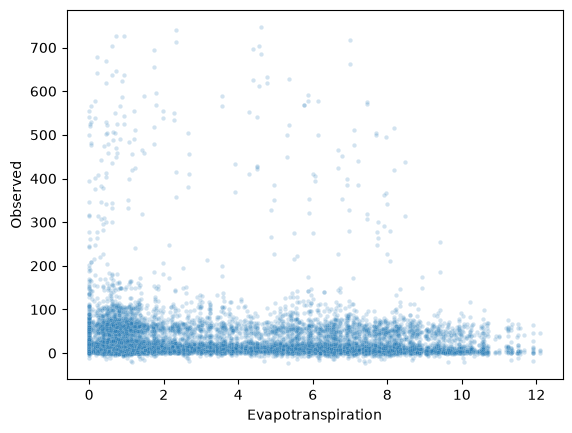

In [20]:
sns.scatterplot(data=df, x='Pumping', y='Observed', alpha=0.2, s=10)
plt.show()
sns.scatterplot(data=df, x='Precipitation', y='Observed', alpha=0.2, s=10)
plt.show()
sns.scatterplot(data=df, x='Evapotranspiration', y='Observed', alpha=0.2, s=10)
plt.show()

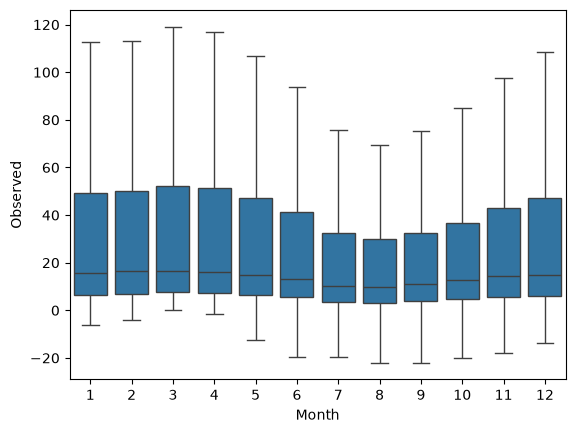

In [21]:
sns.boxplot(data=df, x='Month', y='Observed', showfliers=False)
plt.show()

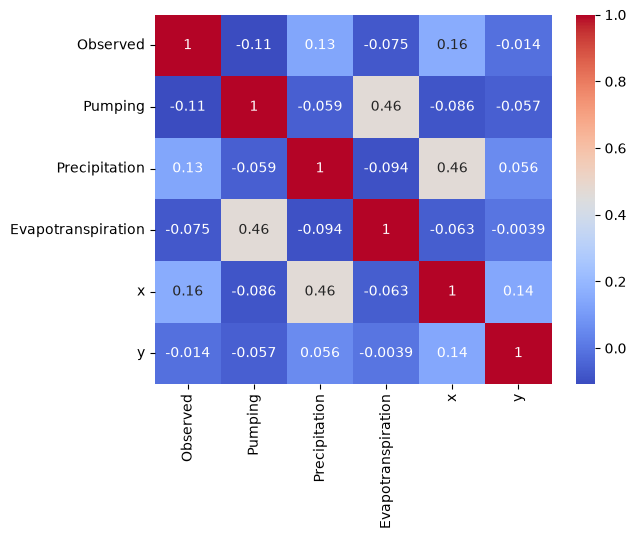

In [22]:
sns.heatmap(df[['Observed', 'Pumping', 'Precipitation', 'Evapotranspiration', 'x', 'y']].corr(), annot=True, cmap='coolwarm')
plt.show()

Correlations over everything are pretty weak. Baseflow is lowest Jul-Sep which is when pumping happens. Pumping and ET are correlated (0.46) since they're both high in summer.